# Kvantumos erőforrás-becslés Q# programokhoz

## Notebook a második előadáshoz

## 0. Telepítés és importok

A telepítés után indítsd újra a Jupyter-kernelt.

In [1]:
# Csak szükség esetén futtasd:
# %pip install --upgrade "qdk[jupyter,qre]" pandas matplotlib ipykernel

In [2]:
import math
import importlib.metadata as metadata
import pandas as pd
import matplotlib.pyplot as plt

from qdk import qsharp, code
from qdk.qre import estimate, plot_estimates, PSSPC, LatticeSurgery
from qdk.qre.application import QSharpApplication
from qdk.qre.models import GateBased, SurfaceCode, RoundBasedFactory

for package in ["qdk", "pandas", "matplotlib"]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: nincs telepítve")

qdk: 1.33.1
pandas: 2.2.3
matplotlib: 3.9.2


# Q# program: összeadó és forgatásokkal kiegészített változat

Az összeadó alkalmas fő példának, mert paraméterezhető, ancillákat és nemtriviális logikai műveleteket használ. A második változat általános forgatásokat ad hozzá, hogy megjelenjen a T-állapot terhelése.

In [3]:
%%qsharp
import Std.Arithmetic.*;

operation EstimateAdder(n : Int) : Unit {
    use a = Qubit[n];
    use b = Qubit[n];
    RippleCarryCGIncByLE(a, b);
    ResetAll(a);
    ResetAll(b);
}

operation EstimateAdderWithRotations(
    n : Int,
    repetitions : Int,
    angle : Double
) : Unit {
    use a = Qubit[n];
    use b = Qubit[n];

    for _ in 1..repetitions {
        for q in a { Rz(angle, q); }
    }

    RippleCarryCGIncByLE(a, b);
    ResetAll(a);
    ResetAll(b);
}

## Alkalmazásmodell és `required_isa`

A `QSharpApplication` a konkrét programot és paramétereit alkalmazásmodellé alakítja. A `required_isa` nem a Q# forrás szó szerinti kapuszámlálója.

In [4]:
app8 = QSharpApplication(code.EstimateAdder, args=(8,))
trace8 = next(app8.enumerate_traces())
display(trace8.required_isa.as_frame())

,encoding,arity
id,,
CCX,LOGICAL,3
MEAS_Z,LOGICAL,1


# A Microsoft QRE keresési tere

- A `trace_query` különböző programtranszformációs konfigurációkat generál, például rotációfelbontást, CCX-megvalósítást és lassítási lehetőségeket.
- Az `isa_query` a fizikai architektúrából különböző QEC- és gyár-konfigurációkkal ISA-kat generál.
- A QRE kompatibilis trace--ISA párokat értékel ki, eldobja a hibakeretet sértő eredményeket, majd Pareto-frontot képez.

In [5]:
architecture = GateBased(
    error_rate=1e-4,
    gate_time=100,
    measurement_time=500,
)

isa_query = SurfaceCode.q() * RoundBasedFactory.q()
trace_query = PSSPC.q() * LatticeSurgery.q()

results = estimate(
    app8,
    architecture,
    isa_query=isa_query,
    trace_query=trace_query,
    max_error=0.01,
)

display(results.as_frame())

,qubits,runtime,error
0,1072,0 days 00:00:00.000084,0.008092


## A megvizsgált konfigurációk száma

A `stats` megmutatja a létrehozott trace-ek, ISA-k, ténylegesen kiértékelt jobok, hibakorlátot teljesítő eredmények és Pareto-pontok számát. A `total_jobs` az eldobások miatt kisebb lehet a `num_traces * num_isas` szorzatnál.

In [6]:
stats = results.stats

stats_table = pd.DataFrame([{
    "trace-ek": stats.num_traces,
    "ISA-k": stats.num_isas,
    "elméleti párok": stats.num_traces * stats.num_isas,
    "kiértékelt jobok": stats.total_jobs,
    "hibakorlát alatt": stats.successful_estimates,
    "Pareto-pontok": stats.pareto_results,
}])

display(stats_table)

if stats.num_traces * stats.num_isas:
    pruning_ratio = 1 - stats.total_jobs / (stats.num_traces * stats.num_isas)
    print(f"Eldobás arány az elméleti Descartes-szorzathoz képest: {pruning_ratio:.1%}")

,trace-ek,ISA-k,elméleti párok,kiértékelt jobok,hibakorlát alatt,Pareto-pontok
0,32,1248,39936,19584,192,1


Eldobás arány az elméleti Descartes-szorzathoz képest: 51.0%


## Részletes eredményoszlopok és Pareto-front

In [7]:
results.add_qubit_partition_column()
results.add_factory_summary_column()
display(results.as_frame())

results.plot(figsize=(8, 5), runtime_unit="ms")
plt.show()

,qubits,runtime,error,physical_compute_qubits,physical_factory_qubits,physical_memory_qubits,factories
0,1072,0 days 00:00:00.000084,0.008092,1071,1,0,1×T


# Kontrollált vizsgálatok

## A. Problémaméret

In [8]:
size_results = {}
for n in [4, 8, 16, 32]:
    app = QSharpApplication(code.EstimateAdder, args=(n,))
    try:
        out = estimate(app, architecture,
                       name=f"n={n}",
                       isa_query=isa_query,
                       trace_query=trace_query,
                       max_error=0.01)
        size_results[n] = out
        print(f"\n=== n={n} ===")
        display(out.as_frame())
    except Exception as exc:
        print(f"n={n}: {type(exc).__name__}: {exc}")


=== n=4 ===


,name,qubits,runtime,error
0,n=4,596,0 days 00:00:00.000036,0.00246



=== n=8 ===


,name,qubits,runtime,error
0,n=8,1072,0 days 00:00:00.000084,0.008092



=== n=16 ===


,name,qubits,runtime,error
0,n=16,5734,0 days 00:00:00.000300,0.006211



=== n=32 ===


,name,qubits,runtime,error
0,n=32,13889,0 days 00:00:00.000620,0.003463


### Pareto-frontok a problémaméret szerint

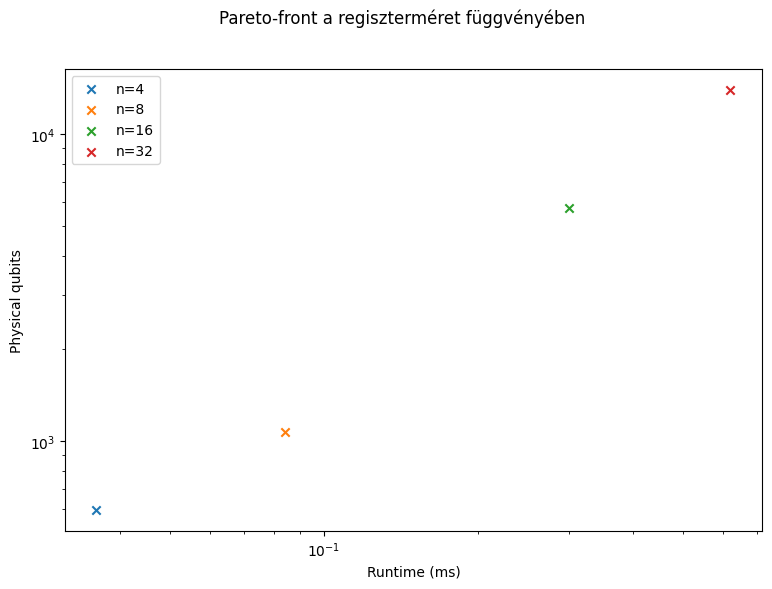

In [9]:
fig = plot_estimates(
    list(size_results.values()),
    runtime_unit="ms",
    figsize=(9, 6),
)
fig.suptitle("Pareto-front a regiszterméret függvényében")
display(fig)

## B. Fizikai hibaarány

In [10]:
error_rate_results = {}
for p in [1e-3, 1e-4, 1e-5]:
    arch = GateBased(error_rate=p, gate_time=100, measurement_time=500)
    try:
        out = estimate(app8, arch,
                       name=f"p={p:.0e}",
                       isa_query=isa_query,
                       trace_query=trace_query,
                       max_error=0.01)
        error_rate_results[p] = out
        print(f"\n=== p={p:.0e} ===")
        display(out.as_frame())
        print("stats:", out.stats)
    except Exception as exc:
        print(f"p={p:.0e}: {type(exc).__name__}: {exc}")


=== p=1e-03 ===


,name,qubits,runtime,error
0,p=1e-03,28903,0 days 00:00:00.000308,0.006018
1,p=1e-03,29743,0 days 00:00:00.000252,0.006494
2,p=1e-03,60431,0 days 00:00:00.000196,0.005889


stats: EstimationTableStats(num_traces=32, num_isas=1248, total_jobs=15840, successful_estimates=320, pareto_results=3)

=== p=1e-04 ===


,name,qubits,runtime,error
0,p=1e-04,1072,0 days 00:00:00.000084,0.008092


stats: EstimationTableStats(num_traces=32, num_isas=1248, total_jobs=19584, successful_estimates=192, pareto_results=1)

=== p=1e-05 ===


,name,qubits,runtime,error
0,p=1e-05,1072,0 days 00:00:00.000084,0.000333


stats: EstimationTableStats(num_traces=32, num_isas=1164, total_jobs=18624, successful_estimates=195, pareto_results=1)


### Pareto-frontok a fizikai hibaarány szerint

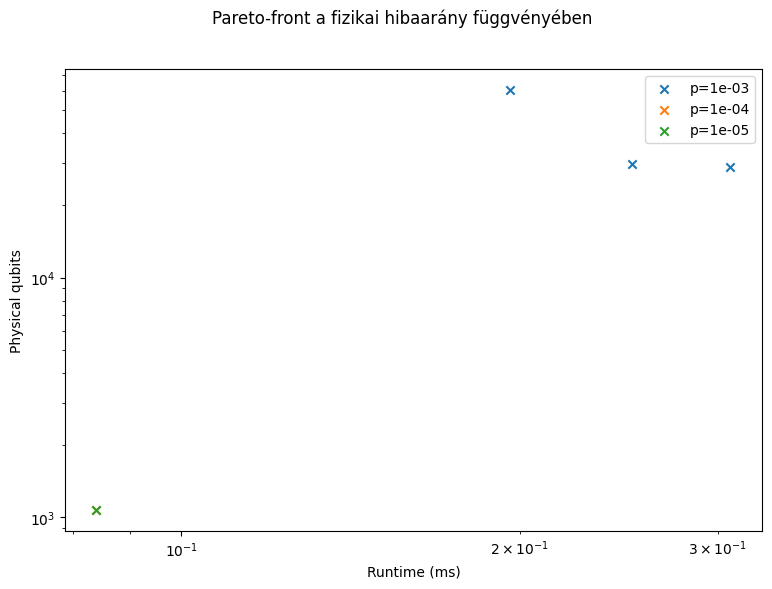

In [11]:
fig = plot_estimates(
    list(error_rate_results.values()),
    runtime_unit="ms",
    figsize=(9, 6),
)
fig.suptitle("Pareto-front a fizikai hibaarány függvényében")
display(fig)

## C. Fizikai műveleti idők

A hibaarányt rögzítjük, és együtt skálázzuk a kapu- és mérési időt. Ez elsősorban a QEC-ciklus és a futásidő időskáláját módosítja.

In [12]:
timing_results = {}
for scale in [1, 5, 10]:
    arch = GateBased(error_rate=1e-4,
                     gate_time=100 * scale,
                     measurement_time=500 * scale)
    out = estimate(app8, arch,
                   name=f"időskála={scale}",
                   isa_query=isa_query,
                   trace_query=trace_query,
                   max_error=0.01)
    timing_results[scale] = out
    print(f"\n=== időskála={scale} ===")
    display(out.as_frame())


=== időskála=1 ===


,name,qubits,runtime,error
0,időskála=1,1072,0 days 00:00:00.000084,0.008092



=== időskála=5 ===


,name,qubits,runtime,error
0,időskála=5,1072,0 days 00:00:00.000420,0.008092



=== időskála=10 ===


,name,qubits,runtime,error
0,időskála=10,1072,0 days 00:00:00.000840,0.008092


### Pareto-frontok az időskála szerint

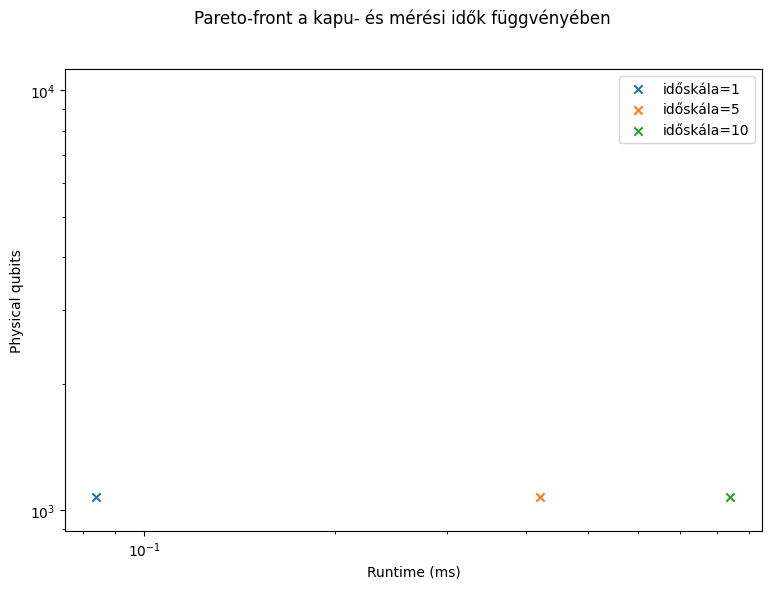

In [13]:
fig = plot_estimates(
    list(timing_results.values()),
    runtime_unit="ms",
    figsize=(9, 6),
)
fig.suptitle("Pareto-front a kapu- és mérési idők függvényében")
display(fig)

## D. Explicit kódtávolság

In [14]:
distance_results = {}
for d in [3, 5, 7, 9, 11]:
    try:
        explicit_isa = SurfaceCode.q(distance=d) * RoundBasedFactory.q()
        out = estimate(app8, architecture,
                       name=f"d={d}",
                       isa_query=explicit_isa,
                       trace_query=trace_query,
                       max_error=0.01)
        distance_results[d] = out
        print(f"\n=== d={d} ===")
        display(out.as_frame())
    except Exception as exc:
        print(f"d={d}: nincs elfogadható konfiguráció ({type(exc).__name__})")


=== d=3 ===


,name,qubits,runtime,error
0,d=3,1072,0 days 00:00:00.000084,0.008092



=== d=5 ===


,name,qubits,runtime,error
0,d=5,3088,0 days 00:00:00.000140,0.002853



=== d=7 ===


,name,qubits,runtime,error
0,d=7,6112,0 days 00:00:00.000196,0.002801



=== d=9 ===


,name,qubits,runtime,error
0,d=9,10144,0 days 00:00:00.000252,0.0028



=== d=11 ===


,name,qubits,runtime,error
0,d=11,15184,0 days 00:00:00.000308,0.0028


### Pareto-frontok a rögzített kódtávolság szerint

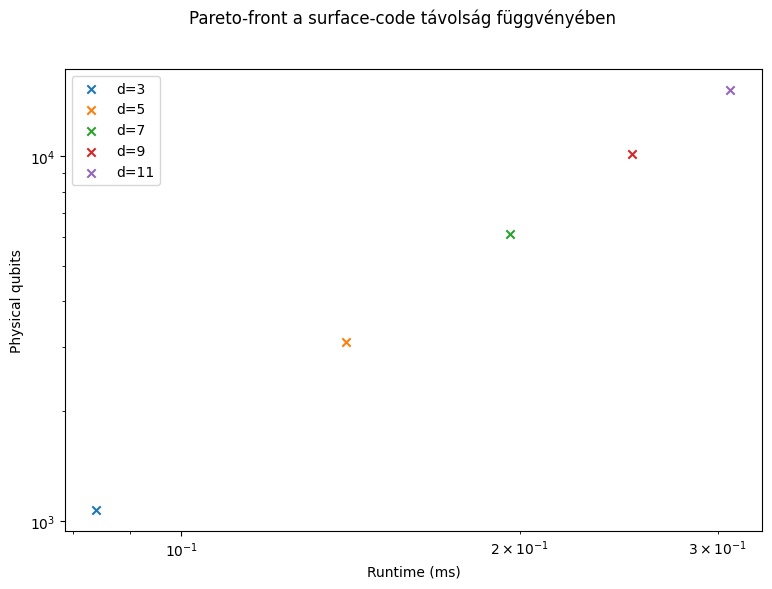

In [15]:
fig = plot_estimates(
    list(distance_results.values()),
    runtime_unit="ms",
    figsize=(9, 6),
)
fig.suptitle("Pareto-front a surface-code távolság függvényében")
display(fig)

# V. Általános forgatások és T-gyárak

Az `Rz(0.3)` nem Clifford-művelet. A hibajavított végrehajtásához T-állapotok szükségesek. Az ismétlésszám növelésével nő a forgatások száma:

$$
N_R = 8r,\qquad r\in\{1,10,100\}.
$$

In [16]:
rotation_apps = {
    r: QSharpApplication(code.EstimateAdderWithRotations, args=(8, r, 0.3))
    for r in [1, 10, 100]
}

rotation_results = {}
for r, app in rotation_apps.items():
    out = estimate(app, architecture,
                   name=f"r={r}",
                   isa_query=isa_query,
                   trace_query=trace_query,
                   max_error=0.01)
    out.add_qubit_partition_column()
    out.add_factory_summary_column()
    rotation_results[r] = out
    print(f"\n=== r={r}; forrásszintű rotációk={8*r} ===")
    display(out.as_frame())
    print("trace/ISA/job/Pareto:",
          out.stats.num_traces,
          out.stats.num_isas,
          out.stats.total_jobs,
          out.stats.pareto_results)


=== r=1; forrásszintű rotációk=8 ===


,name,qubits,runtime,error,physical_compute_qubits,physical_factory_qubits,physical_memory_qubits,factories
0,r=1,9887,0 days 00:00:00.000235,0.005164,3087,6800,0,20×T
1,r=1,38367,0 days 00:00:00.000230,0.009741,3087,35280,0,36×T
2,r=1,61831,0 days 00:00:00.000144,0.009803,1071,60760,0,62×T


trace/ISA/job/Pareto: 32 1248 12928 3

=== r=10; forrásszintű rotációk=80 ===


,name,qubits,runtime,error,physical_compute_qubits,physical_factory_qubits,physical_memory_qubits,factories
0,r=10,40663,0 days 00:00:00.002508,0.007253,15183,25480,0,26×T
1,r=10,41503,0 days 00:00:00.002052,0.007253,10143,31360,0,32×T
2,r=10,47271,0 days 00:00:00.001596,0.007257,6111,41160,0,42×T
3,r=10,60907,0 days 00:00:00.001140,0.007684,3087,57820,0,59×T


trace/ISA/job/Pareto: 32 1248 9801 4

=== r=100; forrásszintű rotációk=800 ===


,name,qubits,runtime,error,physical_compute_qubits,physical_factory_qubits,physical_memory_qubits,factories
0,r=100,44583,0 days 00:00:00.024508,0.007541,15183,29400,0,30×T
1,r=100,46403,0 days 00:00:00.020052,0.007542,10143,36260,0,37×T
2,r=100,52171,0 days 00:00:00.015596,0.007583,6111,46060,0,47×T
3,r=100,69727,0 days 00:00:00.011640,0.008355,3087,66640,0,68×T
4,r=100,183507,0 days 00:00:00.011140,0.009384,3087,180420,0,93×T


trace/ISA/job/Pareto: 32 1248 7623 5


### Pareto-frontok a forgatások száma szerint


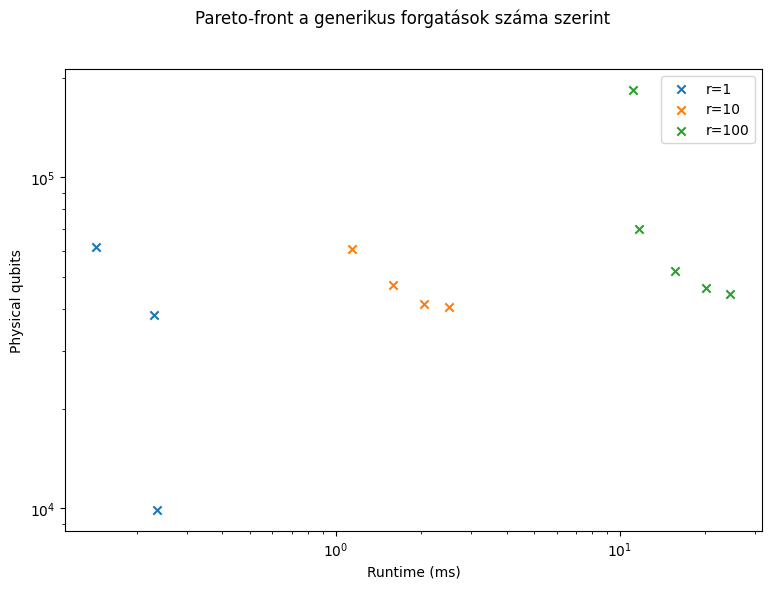

In [17]:
fig = plot_estimates(
    list(rotation_results.values()),
    runtime_unit="ms",
    figsize=(9, 6),
)
fig.suptitle("Pareto-front a generikus forgatások száma szerint")
display(fig)

# VI. Összefoglaló eredménytábla készítése

In [18]:
def first_pareto_row(label, result):
    frame = result.as_frame().reset_index(drop=True)
    row = frame.iloc[0].to_dict()
    return {
        "eset": label,
        "qubit": row.get("qubits"),
        "runtime": row.get("runtime"),
        "error": row.get("error"),
        "trace-ek": result.stats.num_traces,
        "ISA-k": result.stats.num_isas,
        "jobok": result.stats.total_jobs,
        "Pareto-pontok": result.stats.pareto_results,
    }

summary_rows = [first_pareto_row("alap n=8", results)]
summary_rows += [first_pareto_row(f"n={n}", r) for n, r in size_results.items()]
summary_rows += [first_pareto_row(f"p={p:.0e}", r) for p, r in error_rate_results.items()]
summary_rows += [first_pareto_row(f"rotáció r={r}", result)
                 for r, result in rotation_results.items()]

summary = pd.DataFrame(summary_rows)
display(summary)

,eset,qubit,runtime,error,trace-ek,ISA-k,jobok,Pareto-pontok
0,alap n=8,1072,0 days 00:00:00.000084,0.008092,32,1248,19584,1
1,n=4,596,0 days 00:00:00.000036,0.002460,32,1248,19968,1
2,n=8,1072,0 days 00:00:00.000084,0.008092,32,1248,19584,1
3,n=16,5734,0 days 00:00:00.000300,0.006211,32,1248,17952,1
4,n=32,13889,0 days 00:00:00.000620,0.003463,32,1248,17776,1
5,p=1e-03,28903,0 days 00:00:00.000308,0.006018,32,1248,15840,3
6,p=1e-04,1072,0 days 00:00:00.000084,0.008092,32,1248,19584,1
7,p=1e-05,1072,0 days 00:00:00.000084,0.000333,32,1164,18624,1
8,rotáció r=1,9887,0 days 00:00:00.000235,0.005164,32,1248,12928,3
9,rotáció r=10,40663,0 days 00:00:00.002508,0.007253,32,1248,9801,4
